In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

Data source: Seaborn online dataset
Rows: 891 | Columns: 15


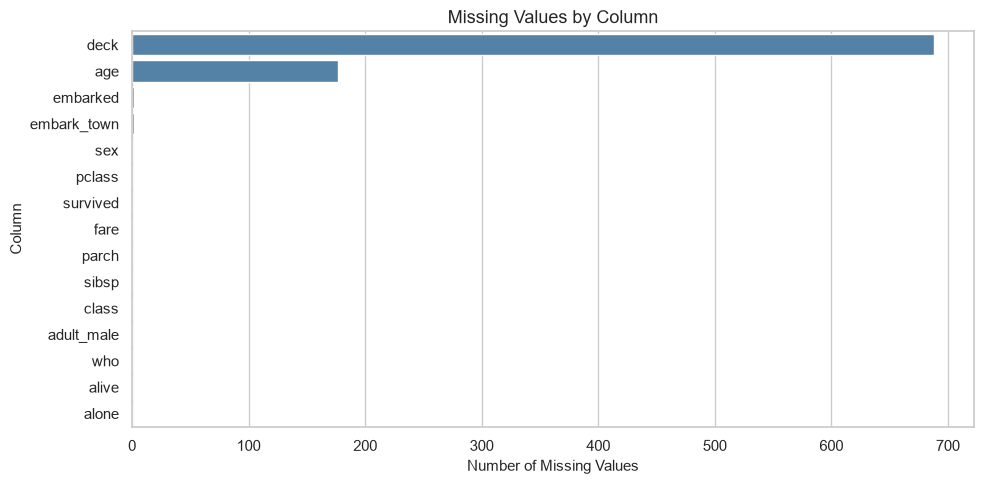

In [3]:
try:
    titanic = sns.load_dataset("titanic")
    data_source = "Seaborn online dataset"
except Exception:
    titanic = pd.read_csv("titanic.csv")
    data_source = "Local titanic.csv file"

print(f"Data source: {data_source}")
print(f"Rows: {titanic.shape[0]:,} | Columns: {titanic.shape[1]:,}")

missing = titanic.isna().sum().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=missing.values, y=missing.index, color="steelblue")
plt.title("Missing Values by Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

Rows included in sex analysis: 891
Sex categories: ['female', 'male']


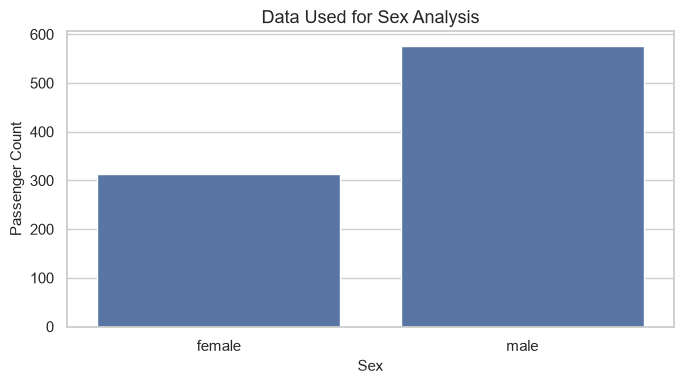

In [4]:
required = {"sex", "survived"}
missing_required = required - set(titanic.columns)
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

titanic["sex"] = titanic["sex"].astype("string").str.strip().str.lower()
sex_data = titanic.dropna(subset=["sex", "survived"]).copy()

sex_data["outcome"] = sex_data["survived"].map({0: "Died", 1: "Survived"})

print(f"Rows included in sex analysis: {len(sex_data):,}")
print("Sex categories:", sorted(sex_data["sex"].unique()))

plt.figure(figsize=(7, 4))
sns.countplot(data=sex_data, x="sex", order=["female", "male"])
plt.title("Data Used for Sex Analysis")
plt.xlabel("Sex")
plt.ylabel("Passenger Count")
plt.tight_layout()
plt.show()

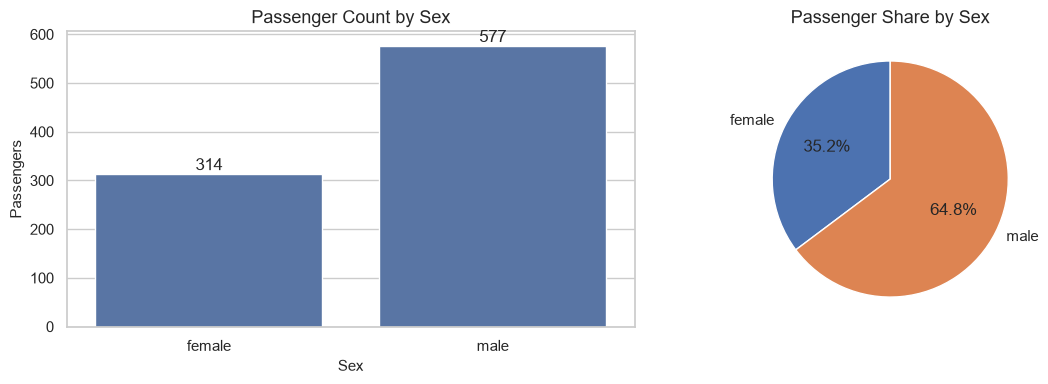

,count,percentage
sex,,
female,314,35.24
male,577,64.76


In [5]:
sex_counts = sex_data["sex"].value_counts().reindex(["female", "male"])
sex_percent = sex_data["sex"].value_counts(normalize=True).reindex(["female", "male"]) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=sex_counts.index, y=sex_counts.values, ax=axes[0])
axes[0].set_title("Passenger Count by Sex")
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("Passengers")
for container in axes[0].containers:
    axes[0].bar_label(container)

axes[1].pie(sex_percent.values, labels=sex_percent.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Passenger Share by Sex")

plt.tight_layout()
plt.show()

display(pd.DataFrame({"count": sex_counts, "percentage": sex_percent.round(2)}))

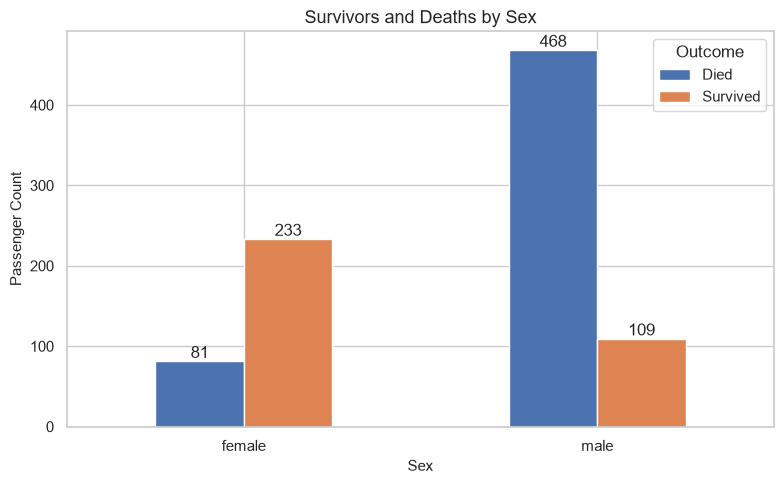

outcome,Died,Survived
sex,,
female,81,233
male,468,109


In [6]:
outcome_counts = pd.crosstab(sex_data["sex"], sex_data["outcome"]).reindex(
    index=["female", "male"], columns=["Died", "Survived"], fill_value=0
)

ax = outcome_counts.plot(kind="bar", figsize=(8, 5), rot=0)
ax.set_title("Survivors and Deaths by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Passenger Count")
ax.legend(title="Outcome")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

display(outcome_counts)

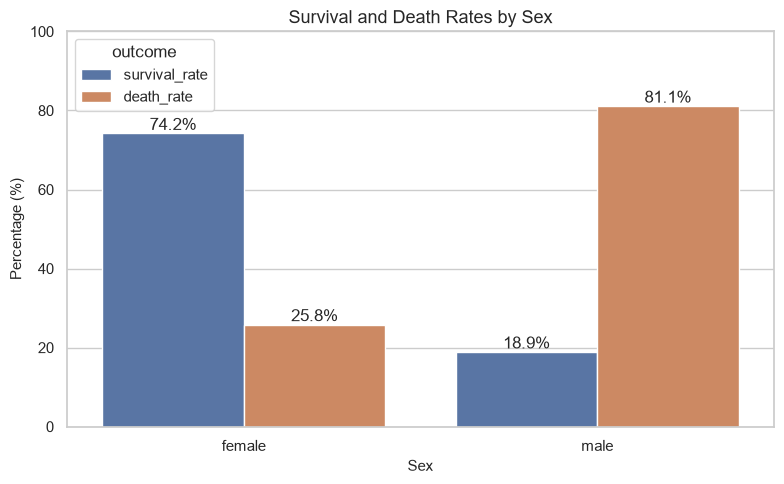

,total,survivors,survival_rate,deaths,death_rate
sex,,,,,
female,314,233,74.20,81,25.80
male,577,109,18.89,468,81.11


In [7]:
gender_rates = sex_data.groupby("sex")["survived"].agg(
    total="count", survivors="sum", survival_rate="mean"
)
gender_rates["deaths"] = gender_rates["total"] - gender_rates["survivors"]
gender_rates["death_rate"] = gender_rates["deaths"] / gender_rates["total"]
gender_rates[["survival_rate", "death_rate"]] *= 100
gender_rates = gender_rates.reindex(["female", "male"])

rate_plot = gender_rates[["survival_rate", "death_rate"]].reset_index().melt(
    id_vars="sex", var_name="outcome", value_name="percentage"
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=rate_plot, x="sex", y="percentage", hue="outcome")
ax.set_title("Survival and Death Rates by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 100)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
plt.tight_layout()
plt.show()

display(gender_rates.round(2))

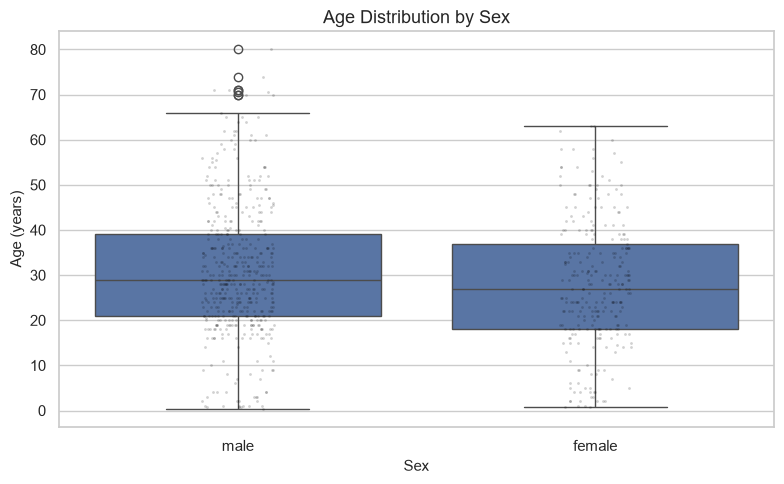

,count,mean,median,min,max
sex,,,,,
female,261,27.92,27.00,0.75,63.00
male,453,30.73,29.00,0.42,80.00


In [8]:
age_data = sex_data.dropna(subset=["age"])
plt.figure(figsize=(8, 5))
sns.boxplot(data=age_data, x="sex", y="age")
sns.stripplot(data=age_data, x="sex", y="age", alpha=0.18, size=2, color="black")
plt.title("Age Distribution by Sex")
plt.xlabel("Sex")
plt.ylabel("Age (years)")
plt.tight_layout()
plt.show()

display(age_data.groupby("sex")["age"].agg(["count", "mean", "median", "min", "max"]).round(2))

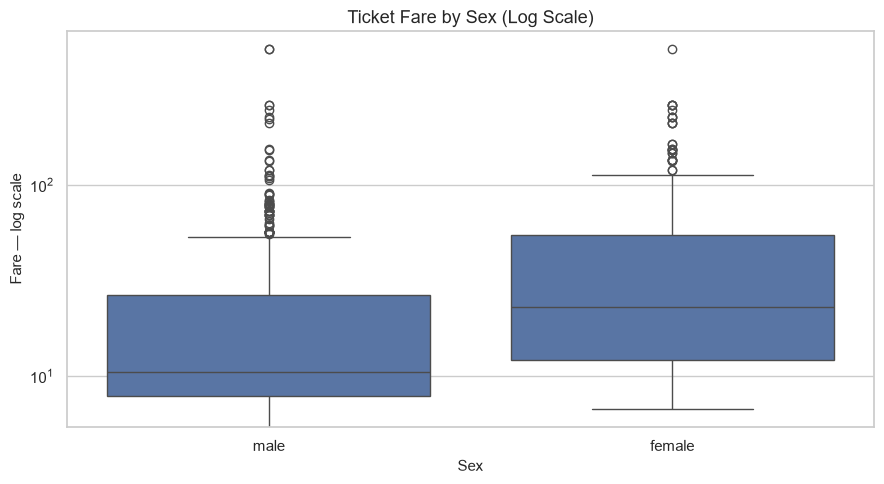

,count,mean,median,minimum,maximum
sex,,,,,
female,314,44.48,23.00,6.75,512.33
male,577,25.52,10.50,0.00,512.33


In [9]:
fare_data = sex_data.dropna(subset=["fare"])
plt.figure(figsize=(9, 5))
sns.boxplot(data=fare_data, x="sex", y="fare")
plt.yscale("log")
plt.title("Ticket Fare by Sex (Log Scale)")
plt.xlabel("Sex")
plt.ylabel("Fare — log scale")
plt.tight_layout()
plt.show()

display(fare_data.groupby("sex")["fare"].agg(
    count="count", mean="mean", median="median", minimum="min", maximum="max"
).round(2))

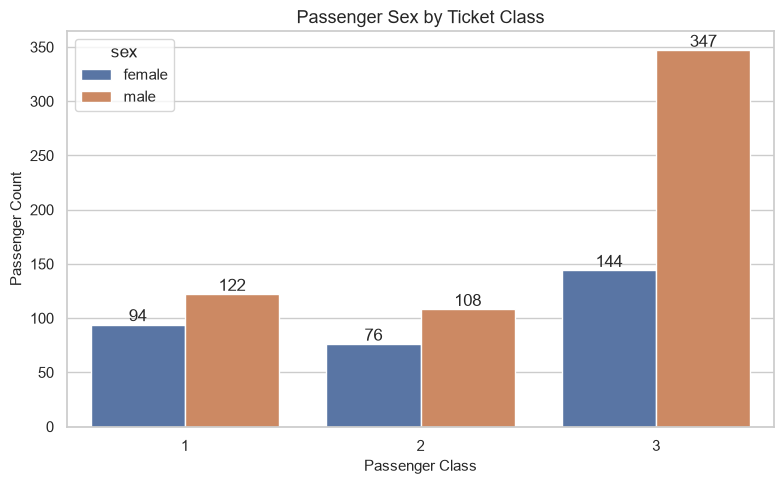

sex,female,male
pclass,,
First,94,122
Second,76,108
Third,144,347


In [10]:
class_data = sex_data.dropna(subset=["pclass"])
class_counts = pd.crosstab(class_data["pclass"], class_data["sex"]).reindex(
    index=[1, 2, 3], columns=["female", "male"], fill_value=0
)

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=class_data, x="pclass", hue="sex", order=[1, 2, 3])
ax.set_title("Passenger Sex by Ticket Class")
ax.set_xlabel("Passenger Class")
ax.set_ylabel("Passenger Count")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

display(class_counts.rename(index={1: "First", 2: "Second", 3: "Third"}))

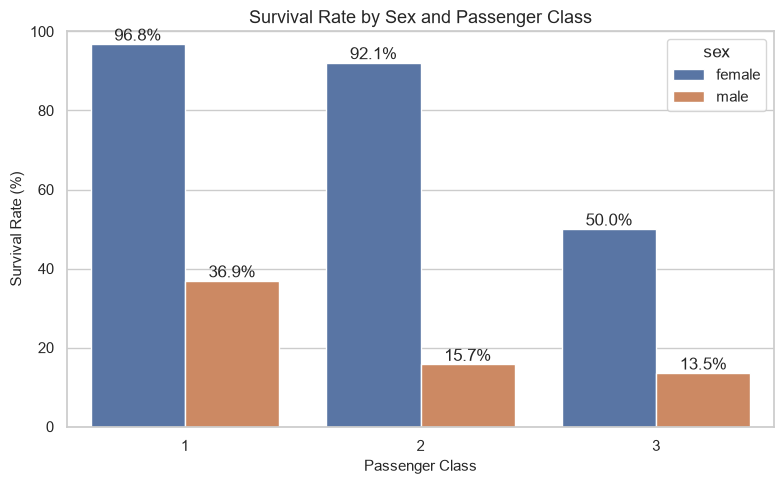

sex,female,male
pclass,,
1,96.81,36.89
2,92.11,15.74
3,50.00,13.54


In [11]:
class_survival = (
    class_data.groupby(["pclass", "sex"])["survived"]
    .mean().mul(100).rename("survival_rate").reset_index()
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=class_survival, x="pclass", y="survival_rate", hue="sex")
ax.set_title("Survival Rate by Sex and Passenger Class")
ax.set_xlabel("Passenger Class")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(0, 100)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
plt.tight_layout()
plt.show()

display(class_survival.pivot(index="pclass", columns="sex", values="survival_rate").round(2))

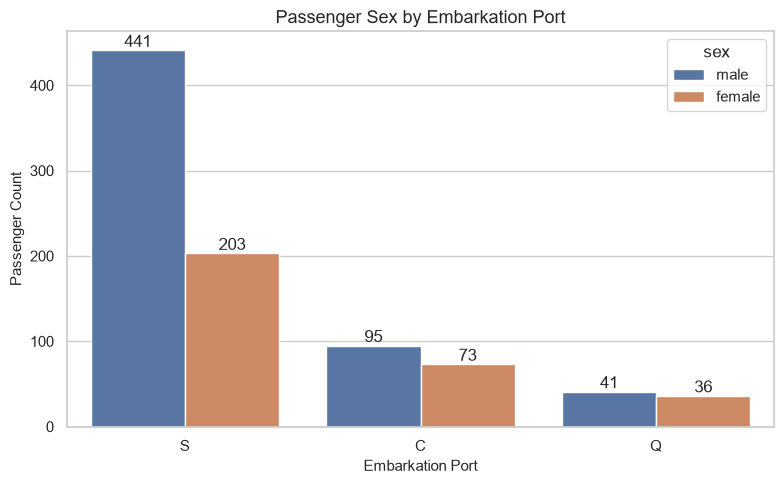

sex,female,male
embarked,,
S,203,441
C,73,95
Q,36,41


In [12]:
port_data = sex_data.dropna(subset=["embarked"])
port_counts = pd.crosstab(port_data["embarked"], port_data["sex"]).reindex(
    index=["S", "C", "Q"], columns=["female", "male"], fill_value=0
)

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=port_data, x="embarked", hue="sex", order=["S", "C", "Q"])
ax.set_title("Passenger Sex by Embarkation Port")
ax.set_xlabel("Embarkation Port")
ax.set_ylabel("Passenger Count")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

display(port_counts)

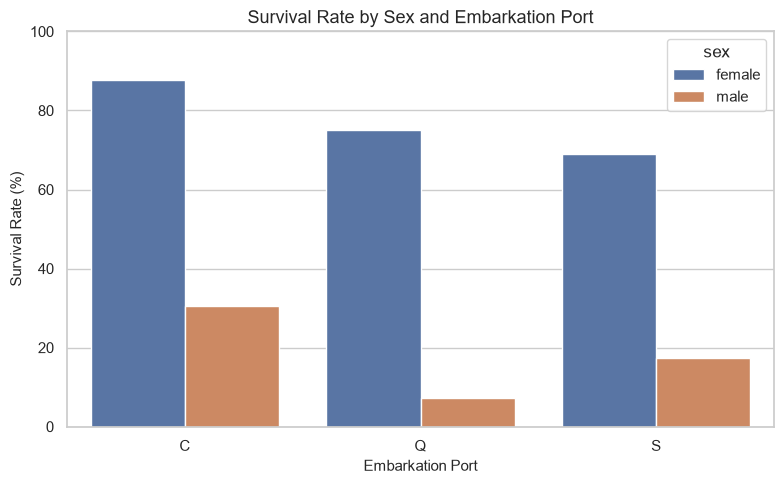

sex,female,male
embarked,,
C,87.67,30.53
Q,75.00,7.32
S,68.97,17.46


In [13]:
port_survival = (
    port_data.groupby(["embarked", "sex"])["survived"]
    .mean().mul(100).rename("survival_rate").reset_index()
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=port_survival, x="embarked", y="survival_rate", hue="sex")
ax.set_title("Survival Rate by Sex and Embarkation Port")
ax.set_xlabel("Embarkation Port")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

display(port_survival.pivot(index="embarked", columns="sex", values="survival_rate").round(2))

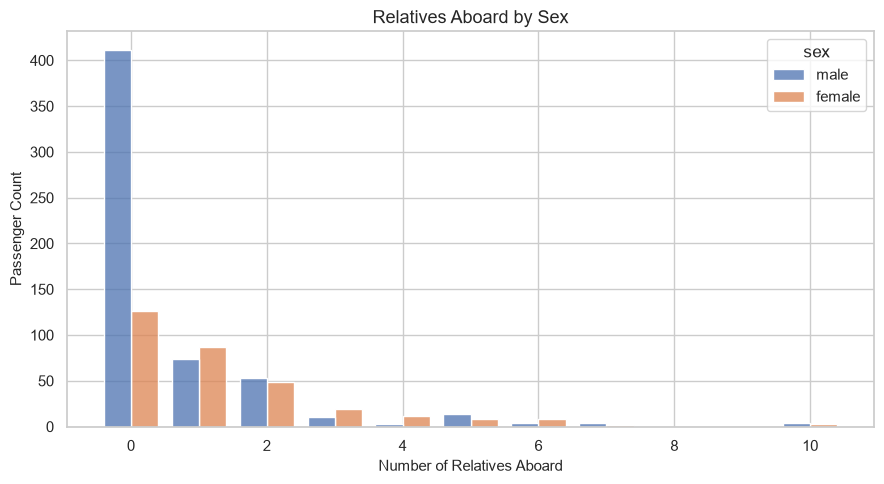

,count,mean,median,max
sex,,,,
female,314,1.34,1.00,10
male,577,0.67,0.00,10


In [14]:
family_data = sex_data.dropna(subset=["sibsp", "parch"]).copy()
family_data["relatives_aboard"] = family_data["sibsp"] + family_data["parch"]

plt.figure(figsize=(9, 5))
sns.histplot(
    data=family_data, x="relatives_aboard", hue="sex",
    discrete=True, multiple="dodge", shrink=0.8
)
plt.title("Relatives Aboard by Sex")
plt.xlabel("Number of Relatives Aboard")
plt.ylabel("Passenger Count")
plt.tight_layout()
plt.show()

display(family_data.groupby("sex")["relatives_aboard"].agg(
    ["count", "mean", "median", "max"]
).round(2))

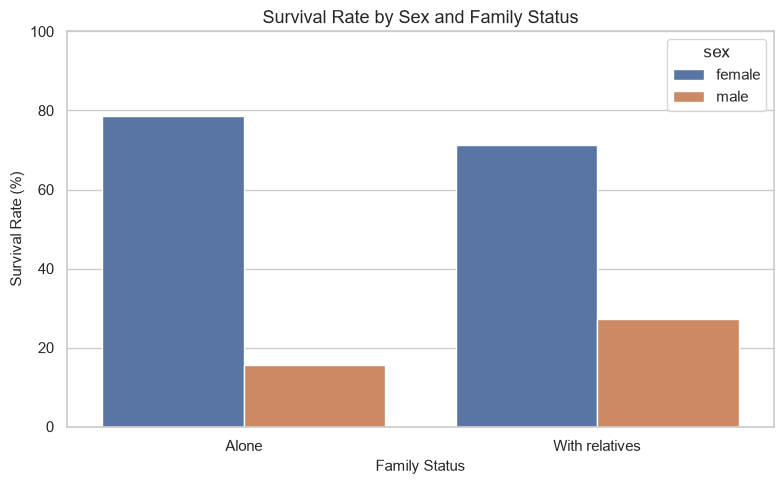

,sex,family_status,survival_rate
0,female,Alone,78.57
1,female,With relatives,71.28
2,male,Alone,15.57
3,male,With relatives,27.11


In [15]:
family_data["family_status"] = np.where(
    family_data["relatives_aboard"].eq(0), "Alone", "With relatives"
)

family_survival = (
    family_data.groupby(["sex", "family_status"])["survived"]
    .mean().mul(100).rename("survival_rate").reset_index()
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=family_survival, x="family_status", y="survival_rate", hue="sex"
)
ax.set_title("Survival Rate by Sex and Family Status")
ax.set_xlabel("Family Status")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

display(family_survival)

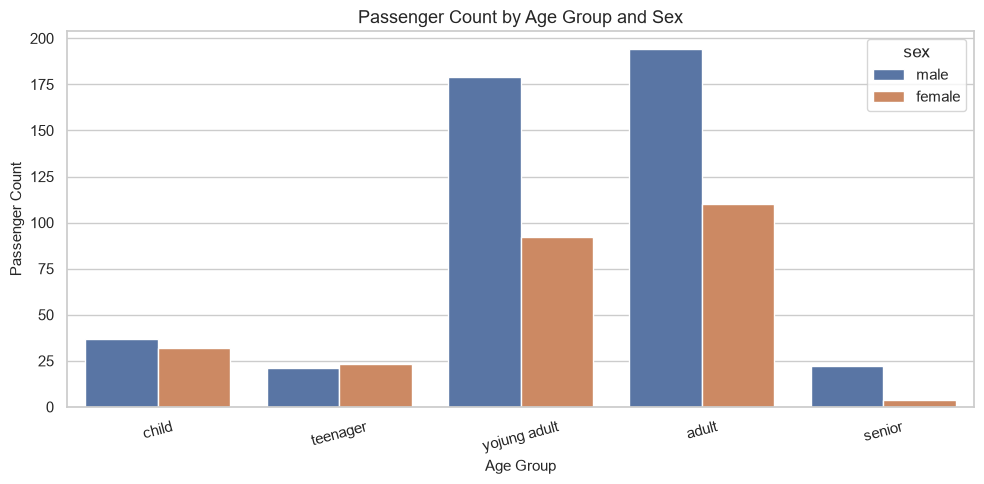

sex,female,male
age_group,,
child,32,37
teenager,23,21
yojung adult,92,179
adult,110,194
senior,4,22


In [16]:
age_group_data = sex_data.dropna(subset=["age"]).copy()
bins = [0, 13, 18, 30, 60, np.inf]
labels = ["child", "teenager", "yojung adult", "adult", "senior"]
age_group_data["age_group"] = pd.cut(
    age_group_data["age"], bins=bins, labels=labels, right=False
)

plt.figure(figsize=(10, 5))
ax = sns.countplot(
    data=age_group_data, x="age_group", hue="sex", order=labels
)
ax.set_title("Passenger Count by Age Group and Sex")
ax.set_xlabel("Age Group")
ax.set_ylabel("Passenger Count")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

display(pd.crosstab(age_group_data["age_group"], age_group_data["sex"]))

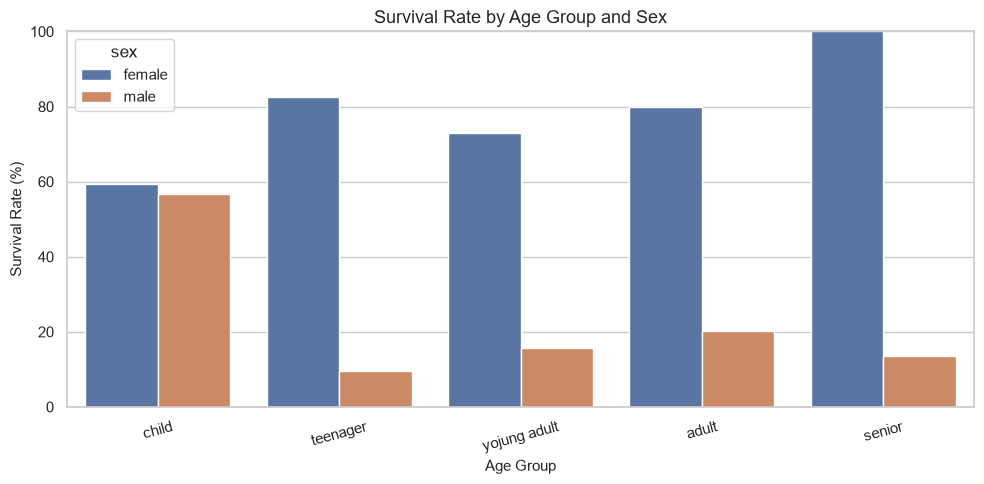

sex,female,male
age_group,,
child,59.38,56.76
teenager,82.61,9.52
yojung adult,72.83,15.64
adult,80.00,20.10
senior,100.00,13.64


In [17]:
age_survival = (
    age_group_data.groupby(["age_group", "sex"], observed=True)["survived"]
    .mean().mul(100).rename("survival_rate").reset_index()
)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=age_survival, x="age_group", y="survival_rate", hue="sex", order=labels
)
ax.set_title("Survival Rate by Age Group and Sex")
ax.set_xlabel("Age Group")
ax.set_ylabel("Survival Rate (%)")
ax.set_ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

display(age_survival.pivot(index="age_group", columns="sex", values="survival_rate").round(2))

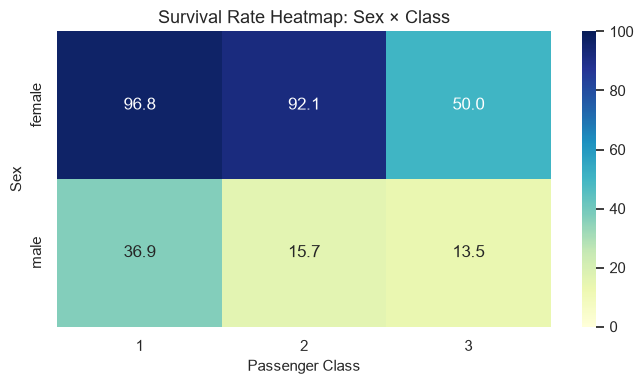

pclass,1,2,3
sex,,,
female,96.81,92.11,50.00
male,36.89,15.74,13.54


In [18]:
survival_heatmap = sex_data.pivot_table(
    index="sex", columns="pclass", values="survived", aggfunc="mean"
).reindex(index=["female", "male"], columns=[1, 2, 3]) * 100

plt.figure(figsize=(7, 4))
sns.heatmap(survival_heatmap, annot=True, fmt=".1f", cmap="YlGnBu", vmin=0, vmax=100)
plt.title("Survival Rate Heatmap: Sex × Class")
plt.xlabel("Passenger Class")
plt.ylabel("Sex")
plt.tight_layout()
plt.show()

display(survival_heatmap.round(2))

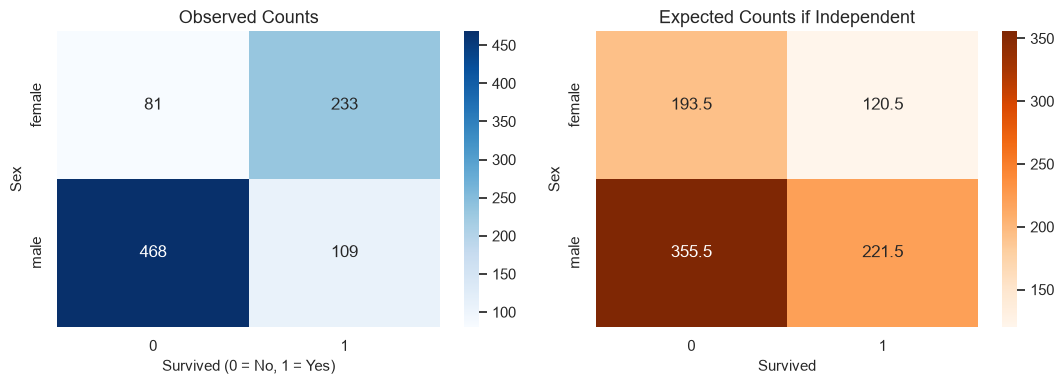

Chi-square statistic: 260.7170
Degrees of freedom: 1
P-value: 1.19736e-58
Interpretation: Evidence of association (p < 0.05).


In [19]:
# Chi-Square (   Gender and survival status are independent, This test examines statistical association and does not establish cause and effect   )

contingency = pd.crosstab(sex_data["sex"], sex_data["survived"])
chi2, p_value, dof, expected = chi2_contingency(contingency)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(contingency, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Observed Counts")
axes[0].set_xlabel("Survived (0 = No, 1 = Yes)")
axes[0].set_ylabel("Sex")

sns.heatmap(
    pd.DataFrame(expected, index=contingency.index, columns=contingency.columns),
    annot=True, fmt=".1f", cmap="Oranges", ax=axes[1]
)
axes[1].set_title("Expected Counts if Independent")
axes[1].set_xlabel("Survived")
axes[1].set_ylabel("Sex")

plt.tight_layout()
plt.show()

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6g}")
print("Interpretation:", "Evidence of association (p < 0.05)." if p_value < 0.05
      else "Insufficient evidence of association (p >= 0.05).")

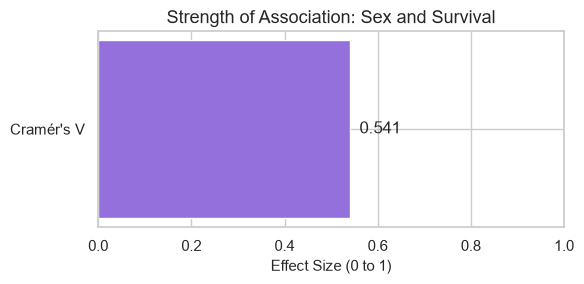

Cramér's V = 0.5409


In [20]:
# Cramér's V (   Statistical significance alone does not indicate the strength of an association. Cramér's V summarizes the strength of the association between two categorical variables on a scale from zero to one   )

n = contingency.to_numpy().sum()
min_dimension = min(contingency.shape[0] - 1, contingency.shape[1] - 1)
cramers_v = np.sqrt(chi2 / (n * min_dimension))

plt.figure(figsize=(6, 3))
plt.barh(["Cramér's V"], [cramers_v], color="mediumpurple")
plt.xlim(0, 1)
plt.xlabel("Effect Size (0 to 1)")
plt.title("Strength of Association: Sex and Survival")
plt.text(cramers_v + 0.02, 0, f"{cramers_v:.3f}", va="center")
plt.tight_layout()
plt.show()

print(f"Cramér's V = {cramers_v:.4f}")

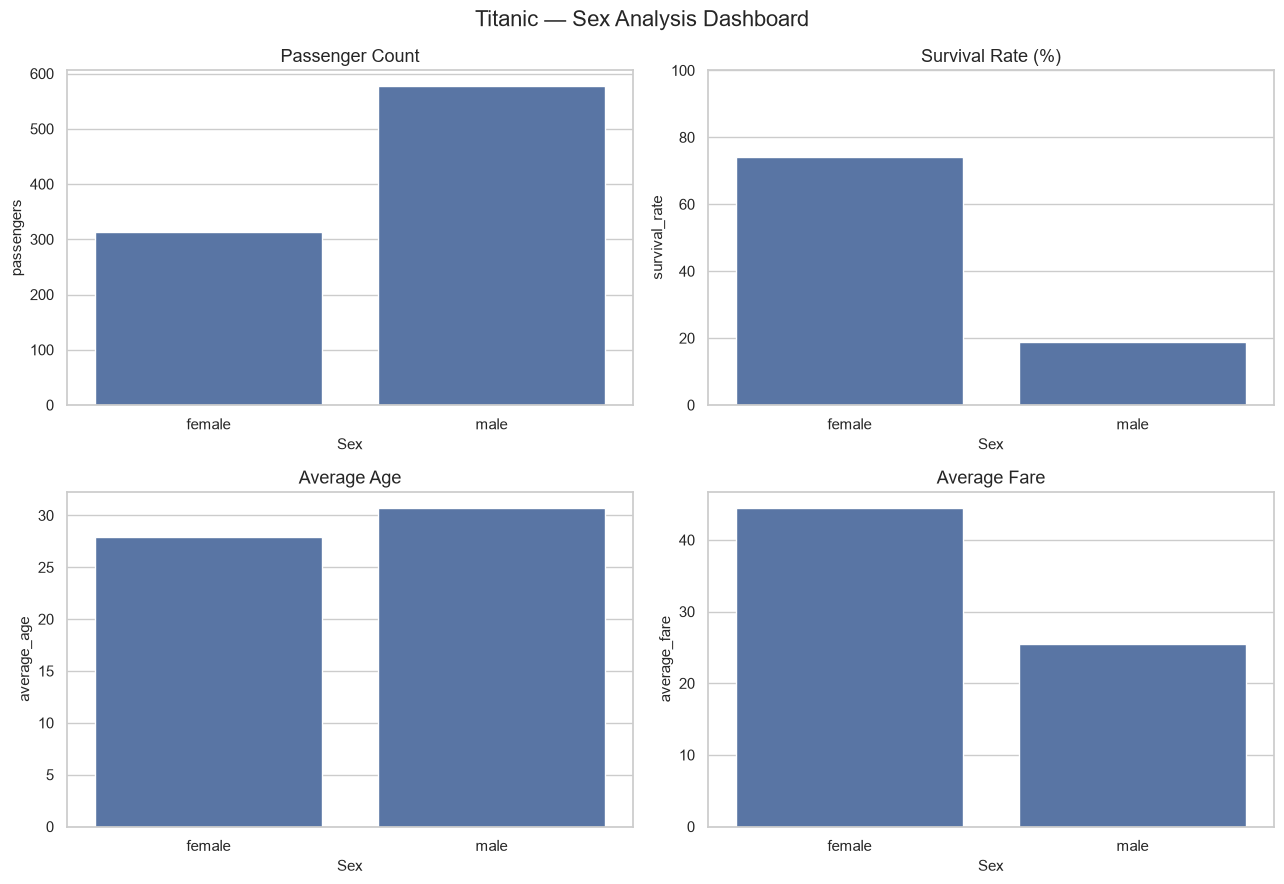

,passengers,survivors,survival_rate,average_age,average_fare
sex,,,,,
female,314,233,74.20,27.92,44.48
male,577,109,18.89,30.73,25.52


In [21]:
summary = sex_data.groupby("sex").agg(
    passengers=("survived", "count"),
    survivors=("survived", "sum"),
    survival_rate=("survived", "mean"),
    average_age=("age", "mean"),
    average_fare=("fare", "mean")
).reindex(["female", "male"])

summary["survival_rate"] *= 100

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.barplot(x=summary.index, y=summary["passengers"], ax=axes[0, 0])
axes[0, 0].set_title("Passenger Count")

sns.barplot(x=summary.index, y=summary["survival_rate"], ax=axes[0, 1])
axes[0, 1].set_title("Survival Rate (%)")
axes[0, 1].set_ylim(0, 100)

sns.barplot(x=summary.index, y=summary["average_age"], ax=axes[1, 0])
axes[1, 0].set_title("Average Age")

sns.barplot(x=summary.index, y=summary["average_fare"], ax=axes[1, 1])
axes[1, 1].set_title("Average Fare")

for ax in axes.flat:
    ax.set_xlabel("Sex")

fig.suptitle("Titanic — Sex Analysis Dashboard", fontsize=16)
plt.tight_layout()
plt.show()

display(summary.round(2))